# US and Canada Product Selection

## 1. Configuration


In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/AustinZhang/Desktop/Capstone/cleaned data")

FILES = {
    "US": DATA_DIR / "valid_US_Enterprise.csv",
    "CA": DATA_DIR / "valid_CA_Enterprise.csv",
}

CORE_PRODUCT_TYPES = ["Notebook", "Workstations", "Desktop", "Visuals"]
PRODUCT_KEYS = ["product_name", "product_family", "product_type"]

# Window settings.
RECENT_MONTHS = 6
HISTORY_PERIOD_MONTHS = 6
HISTORY_PERIODS = 3

# US thresholds: transaction counts must be strictly greater than these values.
US_RECENT_TRANSACTIONS = 100
US_RECENT_ACTIVE_MONTHS = 3
US_HISTORY_TRANSACTIONS = 100
US_MIN_HISTORY_PERIODS = 2

# CA thresholds: transaction counts must be strictly greater than these values.
CA_RECENT_TRANSACTIONS = 50
CA_RECENT_ACTIVE_MONTHS = 3
CA_HISTORY_TRANSACTIONS = 50
CA_MIN_HISTORY_PERIODS = 2

# None uses the month before the latest observed month in both datasets.
# Alternatively, specify a complete month-end date, e.g. "2026-08-31".
SELECTION_CUTOFF = None

## 2. Load Data

In [2]:
country_data = {}

for country, path in FILES.items():
    data = pd.read_csv(
        path,
        low_memory=False,
        dtype={"product_id": "string"},
    )

    ship = pd.to_datetime(data["ship_date"], format="mixed", errors="raise")
    order = pd.to_datetime(data["order_date"], format="mixed", errors="raise")

    # Use ship date when available, otherwise order date.
    data["pricing_date"] = ship.fillna(order)

    assert not data.empty, f"{country}: Empty input."
    assert data["country"].eq(country).all(), f"{country}: Incorrect country."
    assert data["segment"].eq("Enterprise").all(), f"{country}: Incorrect segment."
    assert data["pricing_date"].notna().all(), f"{country}: Missing pricing dates."
    assert (
        data[PRODUCT_KEYS].notna().all().all()
    ), f"{country}: Missing product grouping fields."

    country_data[country] = data.loc[
        data["product_type"].isin(CORE_PRODUCT_TYPES)
    ].copy()

    print(
        f"{country}: {len(data):,} input rows; "
        f"{len(country_data[country]):,} core transaction rows."
    )

US: 2,715,704 input rows; 1,094,431 core transaction rows.
CA: 497,957 input rows; 204,661 core transaction rows.


## 3. Define Windows and Calculate Product Statistics

In [3]:
if SELECTION_CUTOFF is None:
    cutoff_month = min(
        data["pricing_date"].max().to_period("M") - 1 for data in country_data.values()
    )
else:
    date = pd.Timestamp(SELECTION_CUTOFF).normalize()
    cutoff_month = date.to_period("M")

    if date < cutoff_month.end_time.normalize():
        cutoff_month -= 1

end_exclusive = (cutoff_month + 1).to_timestamp()
cutoff_date = end_exclusive - pd.Timedelta(days=1)

recent_start = end_exclusive - pd.DateOffset(months=RECENT_MONTHS)
history_start = recent_start - pd.DateOffset(
    months=HISTORY_PERIOD_MONTHS * HISTORY_PERIODS
)

print(f"Recent window: {recent_start.date()} to {cutoff_date.date()}")
print(
    f"Historical window: {history_start.date()} to "
    f"{(recent_start - pd.Timedelta(days=1)).date()}"
)

history_periods = pd.DataFrame(
    {
        "period_index": range(HISTORY_PERIODS),
        "period_start": [
            history_start + pd.DateOffset(months=HISTORY_PERIOD_MONTHS * i)
            for i in range(HISTORY_PERIODS)
        ],
    }
)

history_periods["period_end"] = history_periods["period_start"].apply(
    lambda date: (
        date + pd.DateOffset(months=HISTORY_PERIOD_MONTHS) - pd.Timedelta(days=1)
    )
)


def build_product_statistics(country):
    data = country_data[country]

    recent = data.loc[
        data["pricing_date"].ge(recent_start) & data["pricing_date"].lt(end_exclusive)
    ].copy()

    historical = data.loc[
        data["pricing_date"].ge(history_start) & data["pricing_date"].lt(recent_start)
    ].copy()

    recent["month"] = recent["pricing_date"].dt.to_period("M")

    # Count rows, preserving duplicate transactions.
    recent_summary = (
        recent.groupby(PRODUCT_KEYS, observed=True)
        .agg(
            recent_transactions=("pricing_date", "size"),
            recent_active_months=("month", "nunique"),
        )
        .reset_index()
    )

    historical["period_index"] = (
        (historical["pricing_date"].dt.year - history_start.year) * 12
        + historical["pricing_date"].dt.month
        - history_start.month
    ) // HISTORY_PERIOD_MONTHS

    historical_counts = (
        historical.groupby(PRODUCT_KEYS + ["period_index"], observed=True)
        .size()
        .rename("transaction_count")
        .reset_index()
    )

    # Evaluate all three historical periods for every recent product.
    history_detail = (
        recent_summary[PRODUCT_KEYS]
        .merge(history_periods, how="cross")
        .merge(
            historical_counts,
            on=PRODUCT_KEYS + ["period_index"],
            how="left",
            validate="one_to_one",
        )
    )

    history_detail["transaction_count"] = (
        history_detail["transaction_count"].fillna(0).astype(int)
    )

    assert recent_summary["recent_transactions"].sum() == len(recent)

    return recent_summary, history_detail


country_results = {}

Recent window: 2026-03-01 to 2026-08-31
Historical window: 2024-09-01 to 2026-02-28


In [4]:
import math
import textwrap
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def plot_selected_transactions(country, products_per_page=20):
    selected = country_results[country]["selected_products"]

    if selected.empty:
        print(f"{country}: No qualifying products.")
        return

    history = (
        country_data[country]
        .loc[country_data[country]["pricing_date"].lt(end_exclusive)]
        .copy()
    )

    data = history.merge(
        selected[PRODUCT_KEYS],
        on=PRODUCT_KEYS,
        how="inner",
        validate="many_to_one",
    )
    data["month"] = data["pricing_date"].dt.to_period("M")

    # Use the same historical timeline for all products within a country.
    months = pd.period_range(
        history["pricing_date"].min().to_period("M"),
        cutoff_month,
        freq="M",
    )

    monthly = (
        data.groupby(PRODUCT_KEYS + ["month"], observed=True)
        .size()
        .rename("transaction_count")
        .reset_index()
    )

    product_counts = {
        key: group.set_index("month")["transaction_count"]
        for key, group in monthly.groupby(PRODUCT_KEYS, observed=True)
    }

    total_pages = math.ceil(len(selected) / products_per_page)

    for page in range(total_pages):
        page_products = selected.iloc[
            page * products_per_page : (page + 1) * products_per_page
        ]

        ncols = 4
        nrows = math.ceil(len(page_products) / ncols)

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(20, 3.2 * nrows),
            sharex=True,
            squeeze=False,
        )

        for ax, (_, product) in zip(axes.flat, page_products.iterrows()):
            key = tuple(product[column] for column in PRODUCT_KEYS)
            recorded = product_counts[key]
            counts = recorded.reindex(months, fill_value=0)

            ax.plot(
                months.to_timestamp(),
                counts.to_numpy(),
                color="steelblue",
                linewidth=1.5,
            )

            # Shade the time before the first recorded transaction.
            first_month = recorded.index.min().to_timestamp()
            if first_month > months[0].to_timestamp():
                ax.axvspan(
                    months[0].to_timestamp(),
                    first_month,
                    color="lightgray",
                    alpha=0.4,
                )

            # Mark the beginning of the recent six-month window.
            ax.axvline(
                recent_start,
                color="darkorange",
                linestyle="--",
                linewidth=1,
            )

            ax.set_title(
                textwrap.fill(str(product["product_name"]), width=38),
                fontsize=9,
                loc="left",
            )
            ax.set_ylim(bottom=0)
            ax.set_xlim(
                months[0].to_timestamp(),
                cutoff_month.end_time.normalize(),
            )
            ax.grid(axis="y", alpha=0.25)
            ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
            ax.tick_params(
                axis="x",
                rotation=45,
                labelsize=8,
                labelbottom=True,
            )
            ax.tick_params(axis="y", labelsize=8)

        for ax in list(axes.flat)[len(page_products) :]:
            ax.set_visible(False)

        fig.suptitle(
            f"{country} — {len(selected)} Qualifying Products "
            f"(Page {page + 1}/{total_pages})\n"
            f"Monthly Transaction Counts Through {cutoff_month}\n"
            "Orange dashed line: start of the recent six-month window",
            fontsize=14,
        )
        fig.supxlabel("Month")
        fig.supylabel("Transaction Rows")
        plt.tight_layout(rect=[0.02, 0.02, 1, 0.92])
        plt.show()

## US Product Selection
- Require more than 100 transactions in total during the latest six complete months, with at least 3 months with transaction record.
- Divide the preceding 18 months into three six-month periods. Require more than 100 transactions in at least two periods.
- Check once every seven days. Each checkpoint represents a prediction for the following seven days and counts as one usable prediction week if:
  - The checkpoint is at least 90 days after the product’s first recorded transaction.
  - There are at least 5 transactions in the 30 days before the checkpoint.
  - There are at least 2 transactions in the seven days after the checkpoint.
- Retain products with at least 9 usable weeks in the latest six months and at least 7 usable weeks in the preceding 18 months.
- Retain all products meeting these requirements

In [5]:
us_recent, us_history = build_product_statistics("US")

us_history["passes_period"] = us_history["transaction_count"].gt(
    US_HISTORY_TRANSACTIONS
)

us_history_summary = (
    us_history.groupby(PRODUCT_KEYS, observed=True)
    .agg(
        history_periods_passed=("passes_period", "sum"),
        historical_transactions=("transaction_count", "sum"),
    )
    .reset_index()
)

us_summary = us_recent.merge(
    us_history_summary,
    on=PRODUCT_KEYS,
    validate="one_to_one",
)

us_summary["qualifies"] = (
    us_summary["recent_transactions"].gt(US_RECENT_TRANSACTIONS)
    & us_summary["recent_active_months"].ge(US_RECENT_ACTIVE_MONTHS)
    & us_summary["history_periods_passed"].ge(US_MIN_HISTORY_PERIODS)
)

us_selected = (
    us_summary.loc[us_summary["qualifies"]]
    .sort_values(PRODUCT_KEYS)
    .reset_index(drop=True)
)

country_results["US"] = {
    "selected_products": us_selected,
    "all_products": us_summary,
    "history_detail": us_history,
}

print(f"US: {len(us_selected)} qualifying product groups.")

US: 76 qualifying product groups.


In [6]:
# Minimum transaction support for a valid forecast sample.
MIN_PAST30_TRANSACTIONS = 5
MIN_FUTURE7_TRANSACTIONS = 2

TOP_N = 30

In [12]:
# Use all initially qualified candidates.
us_candidates = (
    country_results["US"]["all_products"]
    .loc[
        country_results["US"]["all_products"]["qualifies"],
        PRODUCT_KEYS,
    ]
    .copy()
)

us_data = (
    country_data["US"]
    .loc[country_data["US"]["pricing_date"].lt(end_exclusive)]
    .merge(
        us_candidates,
        on=PRODUCT_KEYS,
        how="inner",
        validate="many_to_one",
    )
)

# Weekly forecast dates with complete future seven-day windows.
forecast_dates = pd.date_range(
    start=history_start,
    end=cutoff_date - pd.Timedelta(days=7),
    freq="7D",
)

records = []

for key, product in us_data.groupby(PRODUCT_KEYS, observed=True):
    transaction_counts = product.groupby(product["pricing_date"].dt.normalize()).size()

    daily = transaction_counts.reindex(
        pd.date_range(
            transaction_counts.index.min(),
            cutoff_date,
            freq="D",
        ),
        fill_value=0,
    )

    # Historical features exclude the forecast date.
    past30 = daily.shift(1).rolling(30, min_periods=30).sum()
    past90 = daily.shift(1).rolling(90, min_periods=90).sum()

    # Target window: days t+1 through t+7.
    future7 = daily.shift(-1).iloc[::-1].rolling(7, min_periods=7).sum().iloc[::-1]

    support = pd.DataFrame(
        {
            "past30_transactions": past30,
            "past90_transactions": past90,
            "future7_transactions": future7,
        }
    ).reindex(forecast_dates)

    # This defines a valid sample; it does not filter out products.
    support["valid"] = (
        support["past30_transactions"].ge(MIN_PAST30_TRANSACTIONS)
        & support["past90_transactions"].gt(0)
        & support["future7_transactions"].ge(MIN_FUTURE7_TRANSACTIONS)
    )

    # Historical labels must end before the recent window begins.
    historical = support.loc[support.index + pd.Timedelta(days=7) < recent_start]
    recent = support.loc[support.index >= recent_start]

    historical_valid = int(historical["valid"].sum())
    recent_valid = int(recent["valid"].sum())
    recent_rate = recent_valid / len(recent) if len(recent) > 0 else 0.0

    records.append(
        {
            **dict(zip(PRODUCT_KEYS, key)),
            "history_valid_weeks": historical_valid,
            "recent_valid_weeks": recent_valid,
            "recent_evaluable_weeks": len(recent),
            "recent_valid_week_rate": recent_rate,
        }
    )

us_price_support = pd.DataFrame(
    records,
    columns=PRODUCT_KEYS
    + [
        "history_valid_weeks",
        "recent_valid_weeks",
        "recent_evaluable_weeks",
        "recent_valid_week_rate",
    ],
)

assert len(us_price_support) == len(us_candidates)

print(f"US candidates available: {len(us_price_support)}")

US candidates available: 76


In [ ]:
# Rank all initially qualified candidates
us_ranked = us_price_support.sort_values(
    ["recent_valid_week_rate", "history_valid_weeks"] + PRODUCT_KEYS,
    ascending=[False, False] + [True] * len(PRODUCT_KEYS),
).reset_index(drop=True)

country_results["US"]["price_support_checks"] = us_price_support
country_results["US"]["selected_products"] = us_ranked

In [ ]:
from IPython.display import display

us_usable_week_table = (
    us_price_support[
        PRODUCT_KEYS
        + [
            "recent_valid_weeks",
            "recent_evaluable_weeks",
            "recent_valid_week_rate",
            "history_valid_weeks",
        ]
    ]
    .sort_values(
        ["recent_valid_week_rate", "history_valid_weeks"] + PRODUCT_KEYS,
        ascending=[True, True] + [True] * len(PRODUCT_KEYS),
    )
    .reset_index(drop=True)
    .rename(
        columns={
            "recent_valid_weeks": "recent_usable_weeks",
            "recent_evaluable_weeks": "recent_weeks_checked",
            "recent_valid_week_rate": "recent_usable_week_rate",
            "history_valid_weeks": "historical_usable_weeks",
        }
    )
)

print(f"US — Usable Week Summary ({len(us_usable_week_table)} product groups)")

with pd.option_context(
    "display.max_rows",
    None,
    "display.max_colwidth",
    None,
):
    display(
        us_usable_week_table.style.format(
            {
                "recent_usable_week_rate": "{:.1%}",
            }
        )
    )

US — Usable Week Summary (76 product groups)


,product_name,product_family,product_type,recent_usable_weeks,recent_weeks_checked,recent_usable_week_rate,historical_usable_weeks
0,FO BO C76 JET X1 F5_ESS 21H 293K 69Z,Product Family Knight Thrive,Notebook,2,26,7.7%,2
1,P19 H3,Product Family Knight Thrive,Notebook,5,26,19.2%,9
2,58OUYK5D87 SIGNAL WAY,Product Family Solar Peak,Workstations,5,26,19.2%,51
3,NOVEMBER INTEGRAL V1 PARCEL H48 SUN 95XO,Product Family Frame Road,Notebook,6,26,23.1%,32
4,PIONEER FO Z11H SUN 0_Q470_CTZN_HI_D,Product Family Titan Onset,Desktop,7,26,26.9%,14
5,INTEGRAL SOLSTICE R0 1-EE-2 Z32 ARC 50FZ,Product Family Frame Road,Notebook,8,26,30.8%,18
6,LI ON W78 RAY Z8 H7 35N 710K 65G,Product Family Knight Thrive,Notebook,8,26,30.8%,55
7,WHISKEY KN N31E SUN 1 E7528 60R E A01V,Product Family Titan Onset,Desktop,9,26,34.6%,9
8,HORIZON CA V87H RAY 3 H9562 92X H G15U,Product Family Titan Onset,Desktop,9,26,34.6%,17
9,78VCN39008 THRIVE RAY,Product Family Frame Road,Notebook,9,26,34.6%,21


In [ ]:
MIN_RECENT_USABLE_WEEKS = 9
MIN_HISTORY_USABLE_WEEKS = 7

# Retain products meeting both minimum requirements.
us_retained = (
    us_price_support.loc[
        us_price_support["recent_valid_weeks"].ge(MIN_RECENT_USABLE_WEEKS)
        & us_price_support["history_valid_weeks"].ge(MIN_HISTORY_USABLE_WEEKS)
    ]
    .sort_values(
        ["recent_valid_week_rate", "history_valid_weeks"] + PRODUCT_KEYS,
        ascending=[True, True] + [True] * len(PRODUCT_KEYS),
    )
    .reset_index(drop=True)
)

# Update the selection used by subsequent plots.
country_results["US"]["selected_products"] = us_retained.copy()

print(
    f"US: {len(us_price_support)} initial candidates; "
    f"{len(us_retained)} retained; "
    f"{len(us_price_support) - len(us_retained)} removed."
)

table = us_retained[
    PRODUCT_KEYS
    + [
        "recent_valid_weeks",
        "recent_evaluable_weeks",
        "recent_valid_week_rate",
        "history_valid_weeks",
    ]
].rename(
    columns={
        "recent_valid_weeks": "recent_usable_weeks",
        "recent_evaluable_weeks": "recent_weeks_checked",
        "recent_valid_week_rate": "recent_usable_week_rate",
        "history_valid_weeks": "historical_usable_weeks",
    }
)

with pd.option_context(
    "display.max_rows",
    None,
    "display.max_colwidth",
    None,
):
    display(
        table.style.format(
            {
                "recent_usable_week_rate": "{:.1%}",
            }
        )
    )

US: 76 initial candidates; 65 retained; 11 removed.


,product_name,product_family,product_type,recent_usable_weeks,recent_weeks_checked,recent_usable_week_rate,historical_usable_weeks
0,WHISKEY KN N31E SUN 1 E7528 60R E A01V,Product Family Titan Onset,Desktop,9,26,34.6%,9
1,HORIZON CA V87H RAY 3 H9562 92X H G15U,Product Family Titan Onset,Desktop,9,26,34.6%,17
2,78VCN39008 THRIVE RAY,Product Family Frame Road,Notebook,9,26,34.6%,21
3,73QY858QLX SIGNAL ARC,Product Family Frame Road,Notebook,9,26,34.6%,22
4,NOVEMBER JUNCTION N7 3-OI-4 V42 ARC 07RN,Product Family Frame Road,Notebook,9,26,34.6%,23
5,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Product Family Frame Road,Notebook,9,26,34.6%,49
6,LANTERN KN O70A RAY 1 W6556 63T 1J O15G,Product Family Titan Onset,Desktop,10,26,38.5%,8
7,CIVICCOHC 95 R6 WAY,Product Family Knight Thrive,Notebook,10,26,38.5%,47
8,A61L(P88238IC4)21MAWP OGEEJQU(CEQV N),Product Family Quest Lunar,Visuals,10,26,38.5%,76
9,CYPRESS WH M10I SUN 4 N5072 36Q L V55I,Product Family Titan Onset,Desktop,11,26,42.3%,8


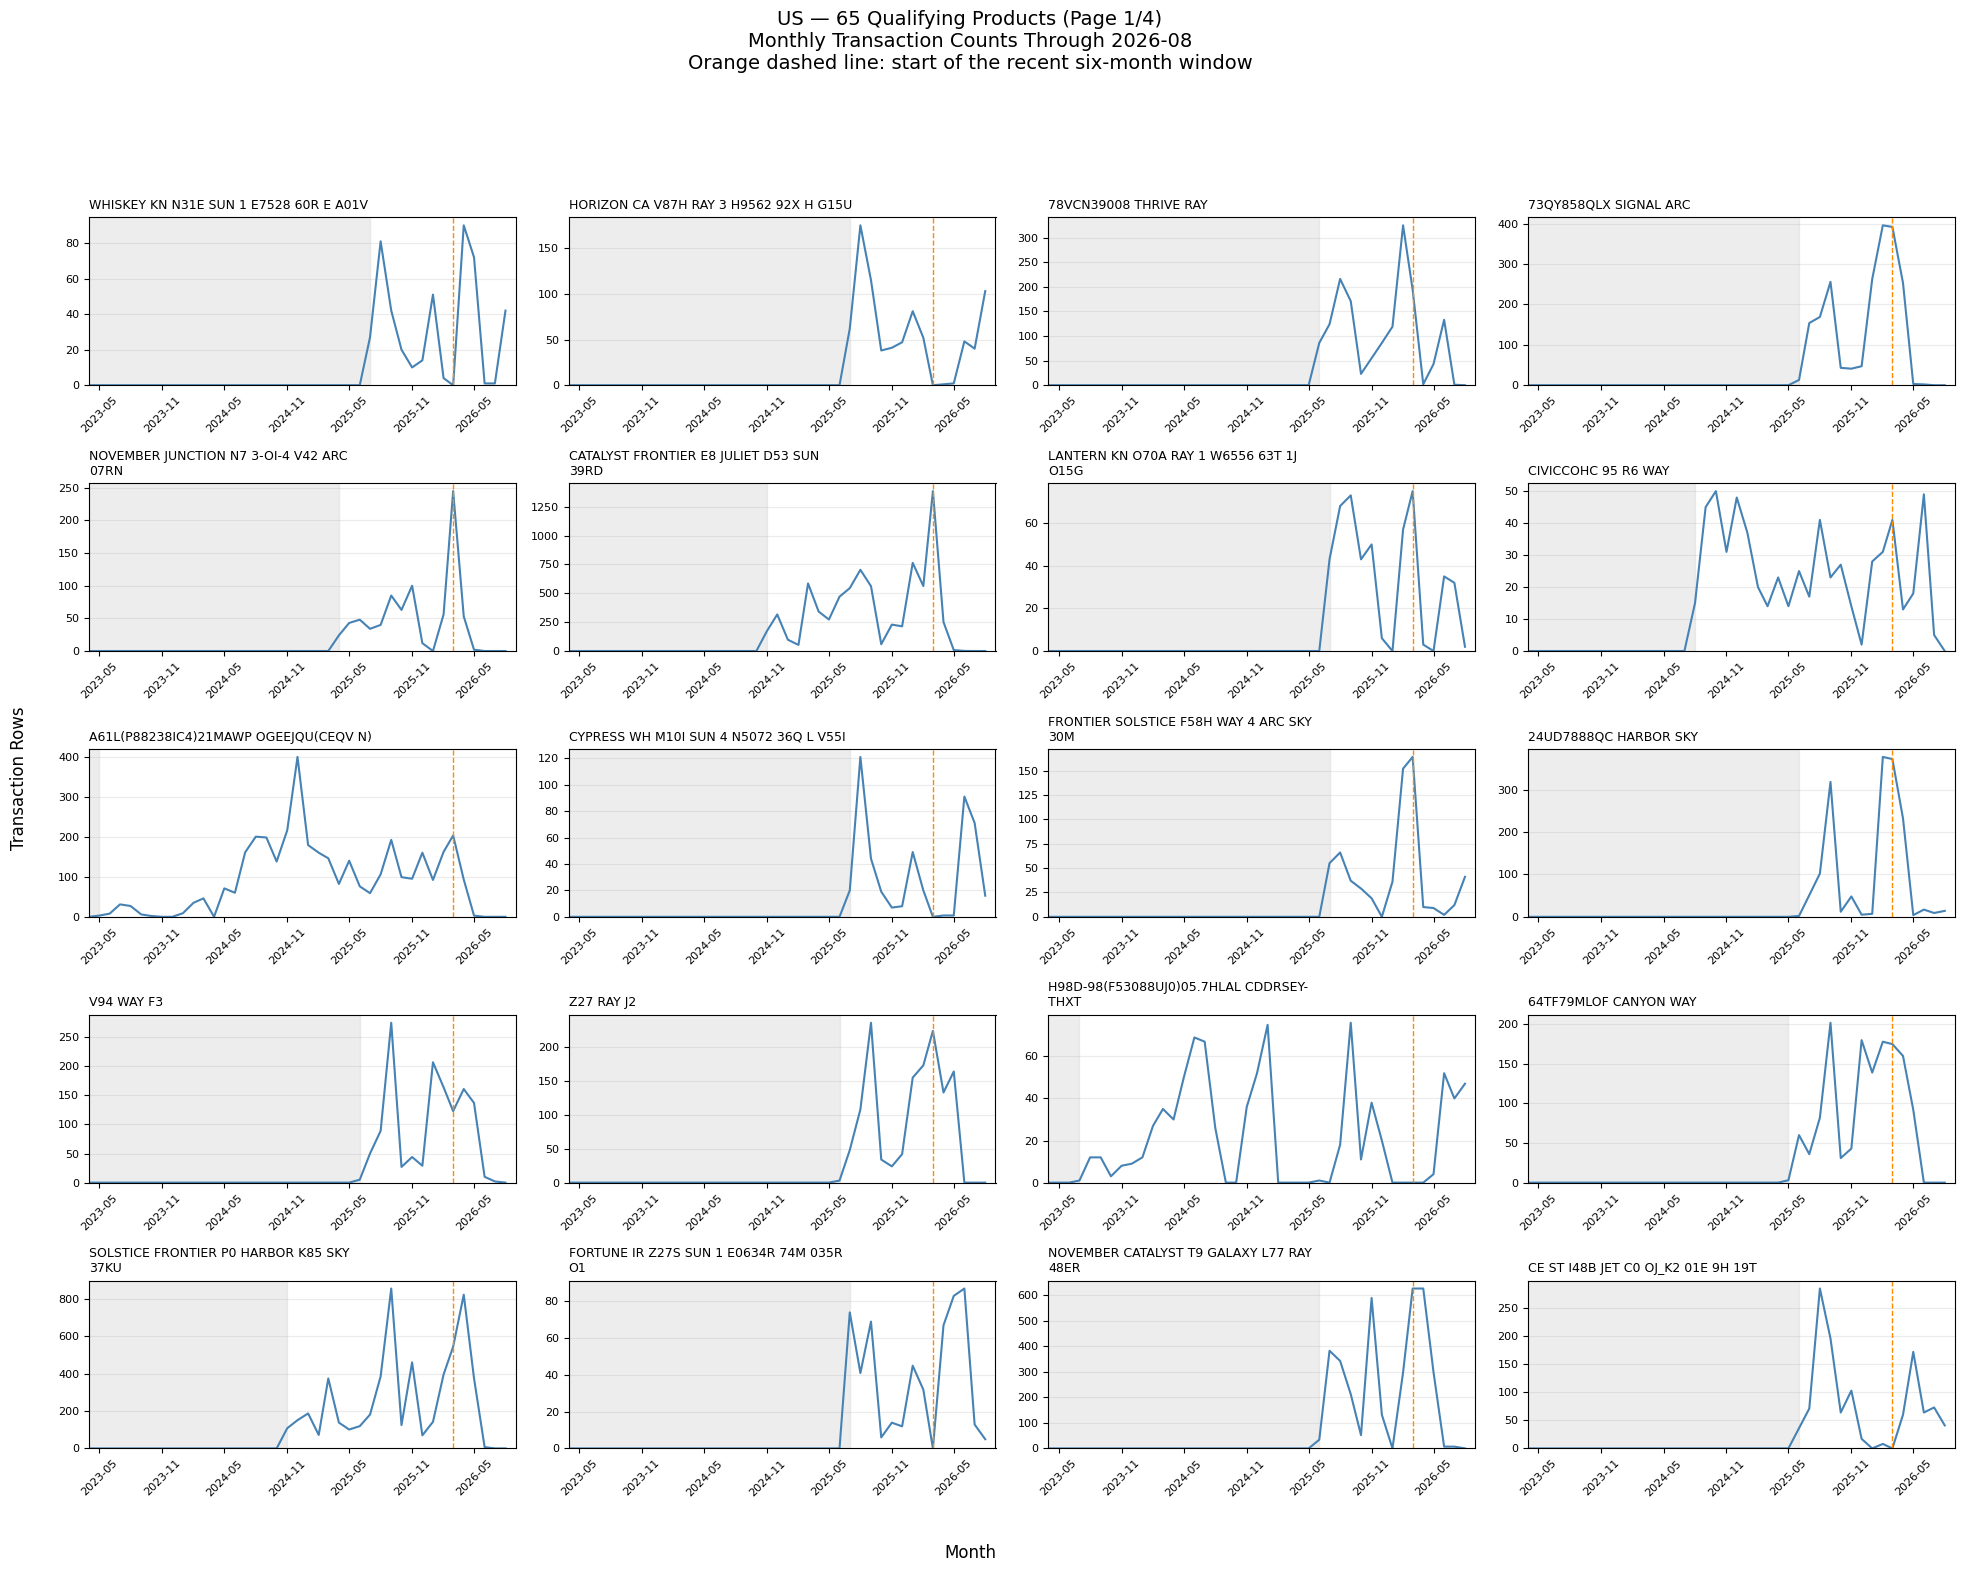

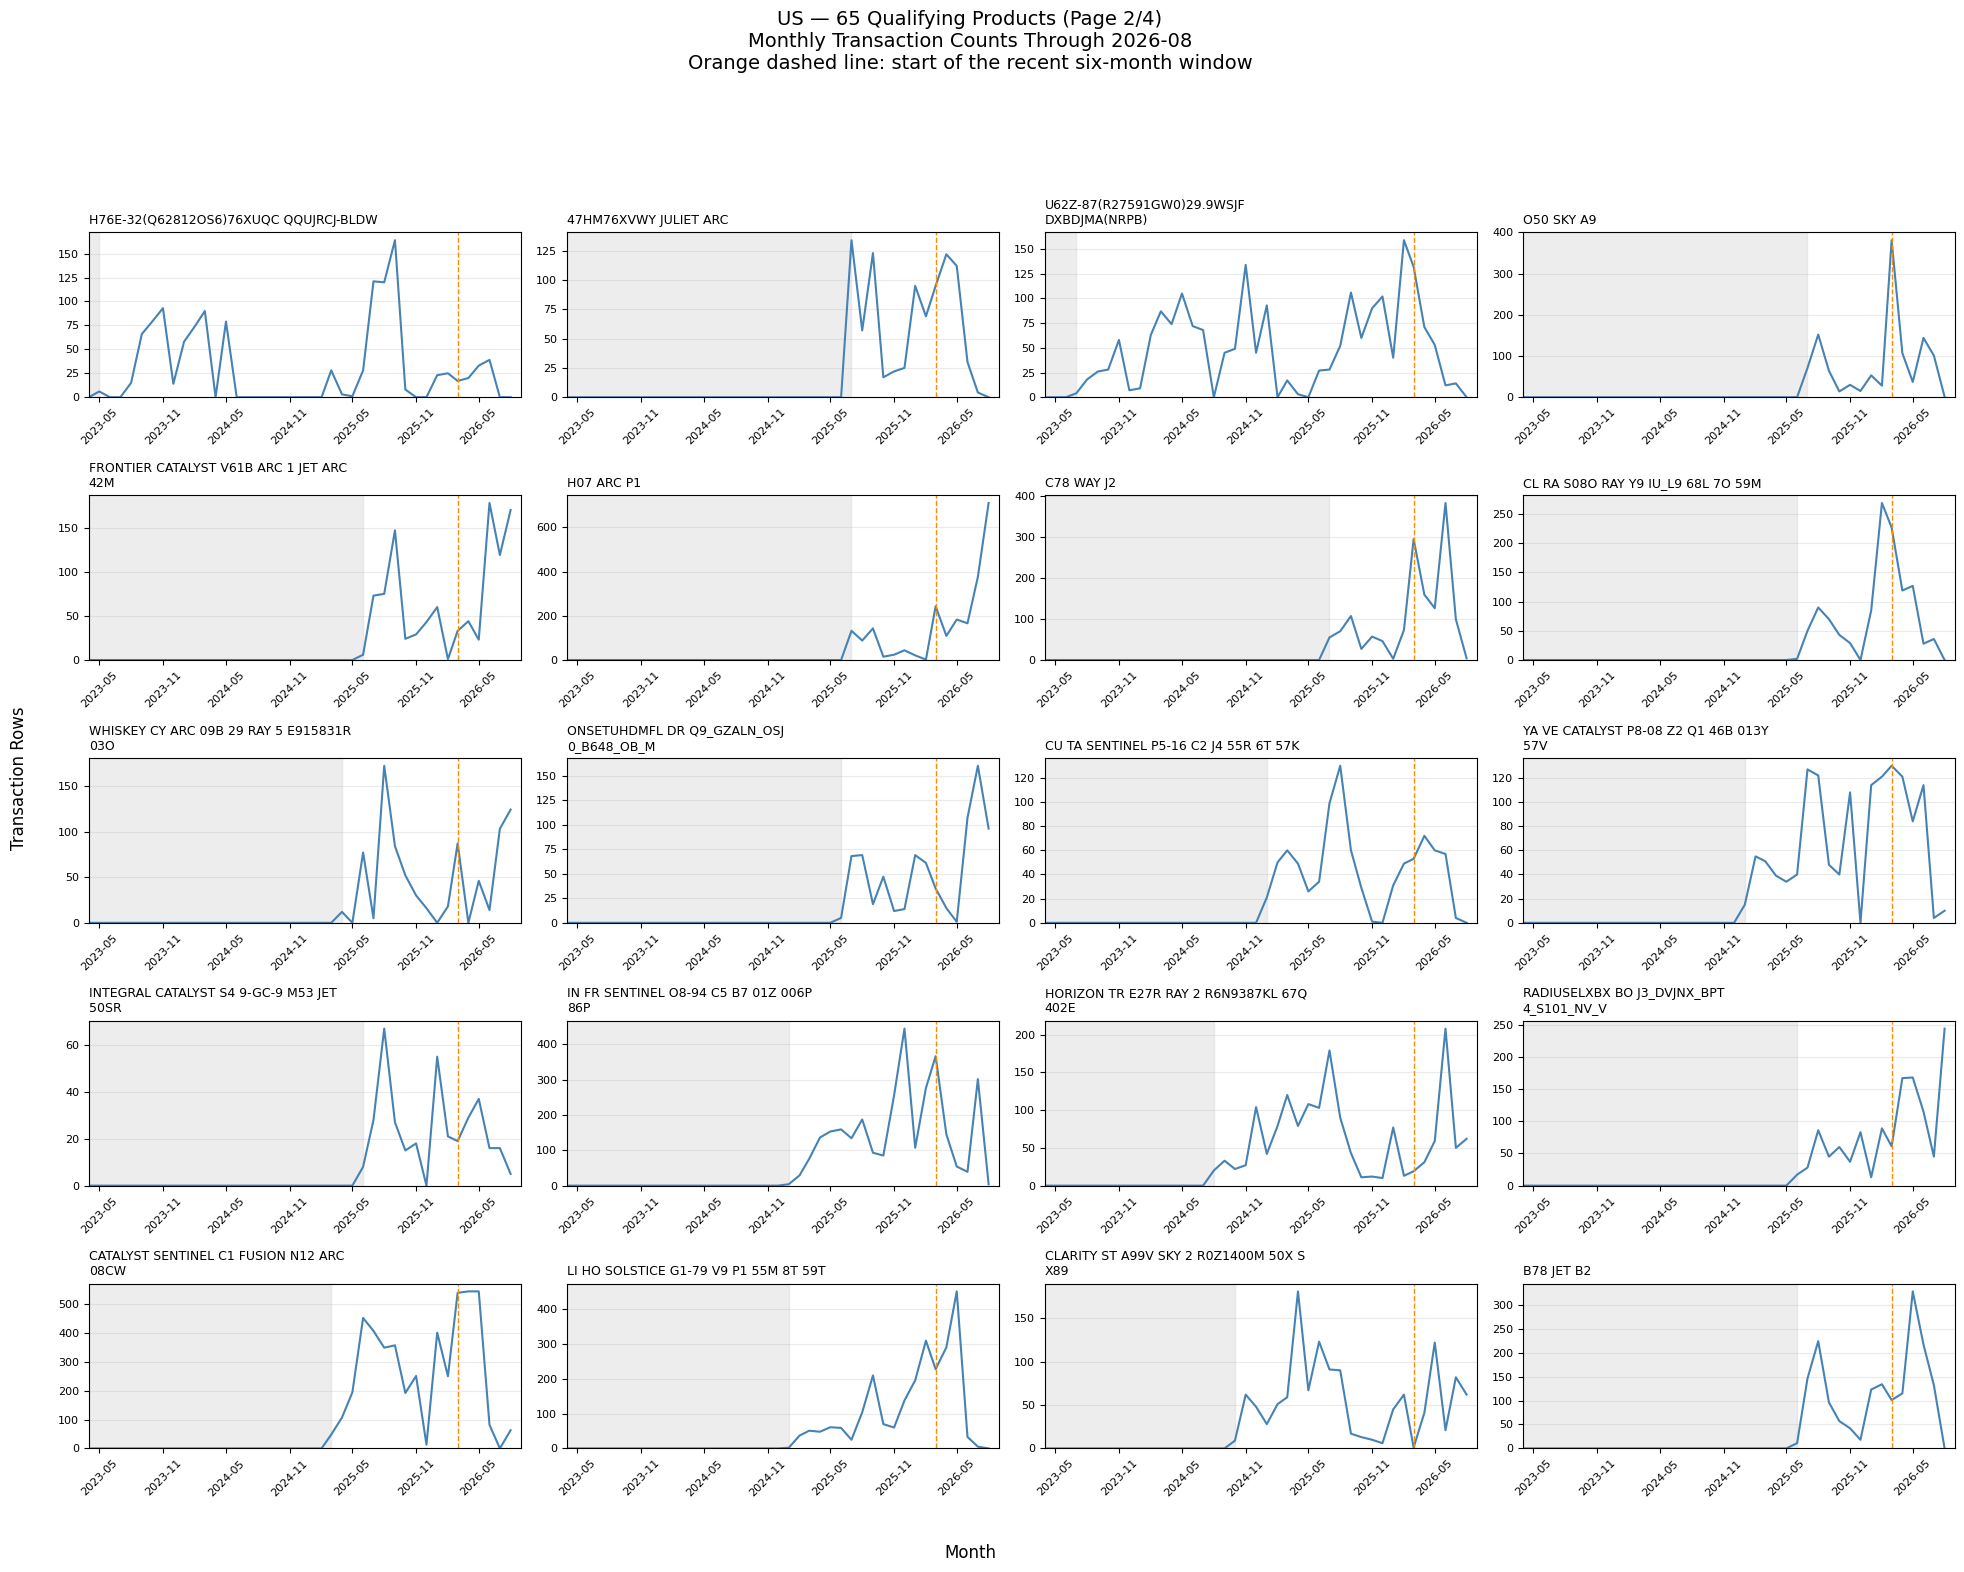

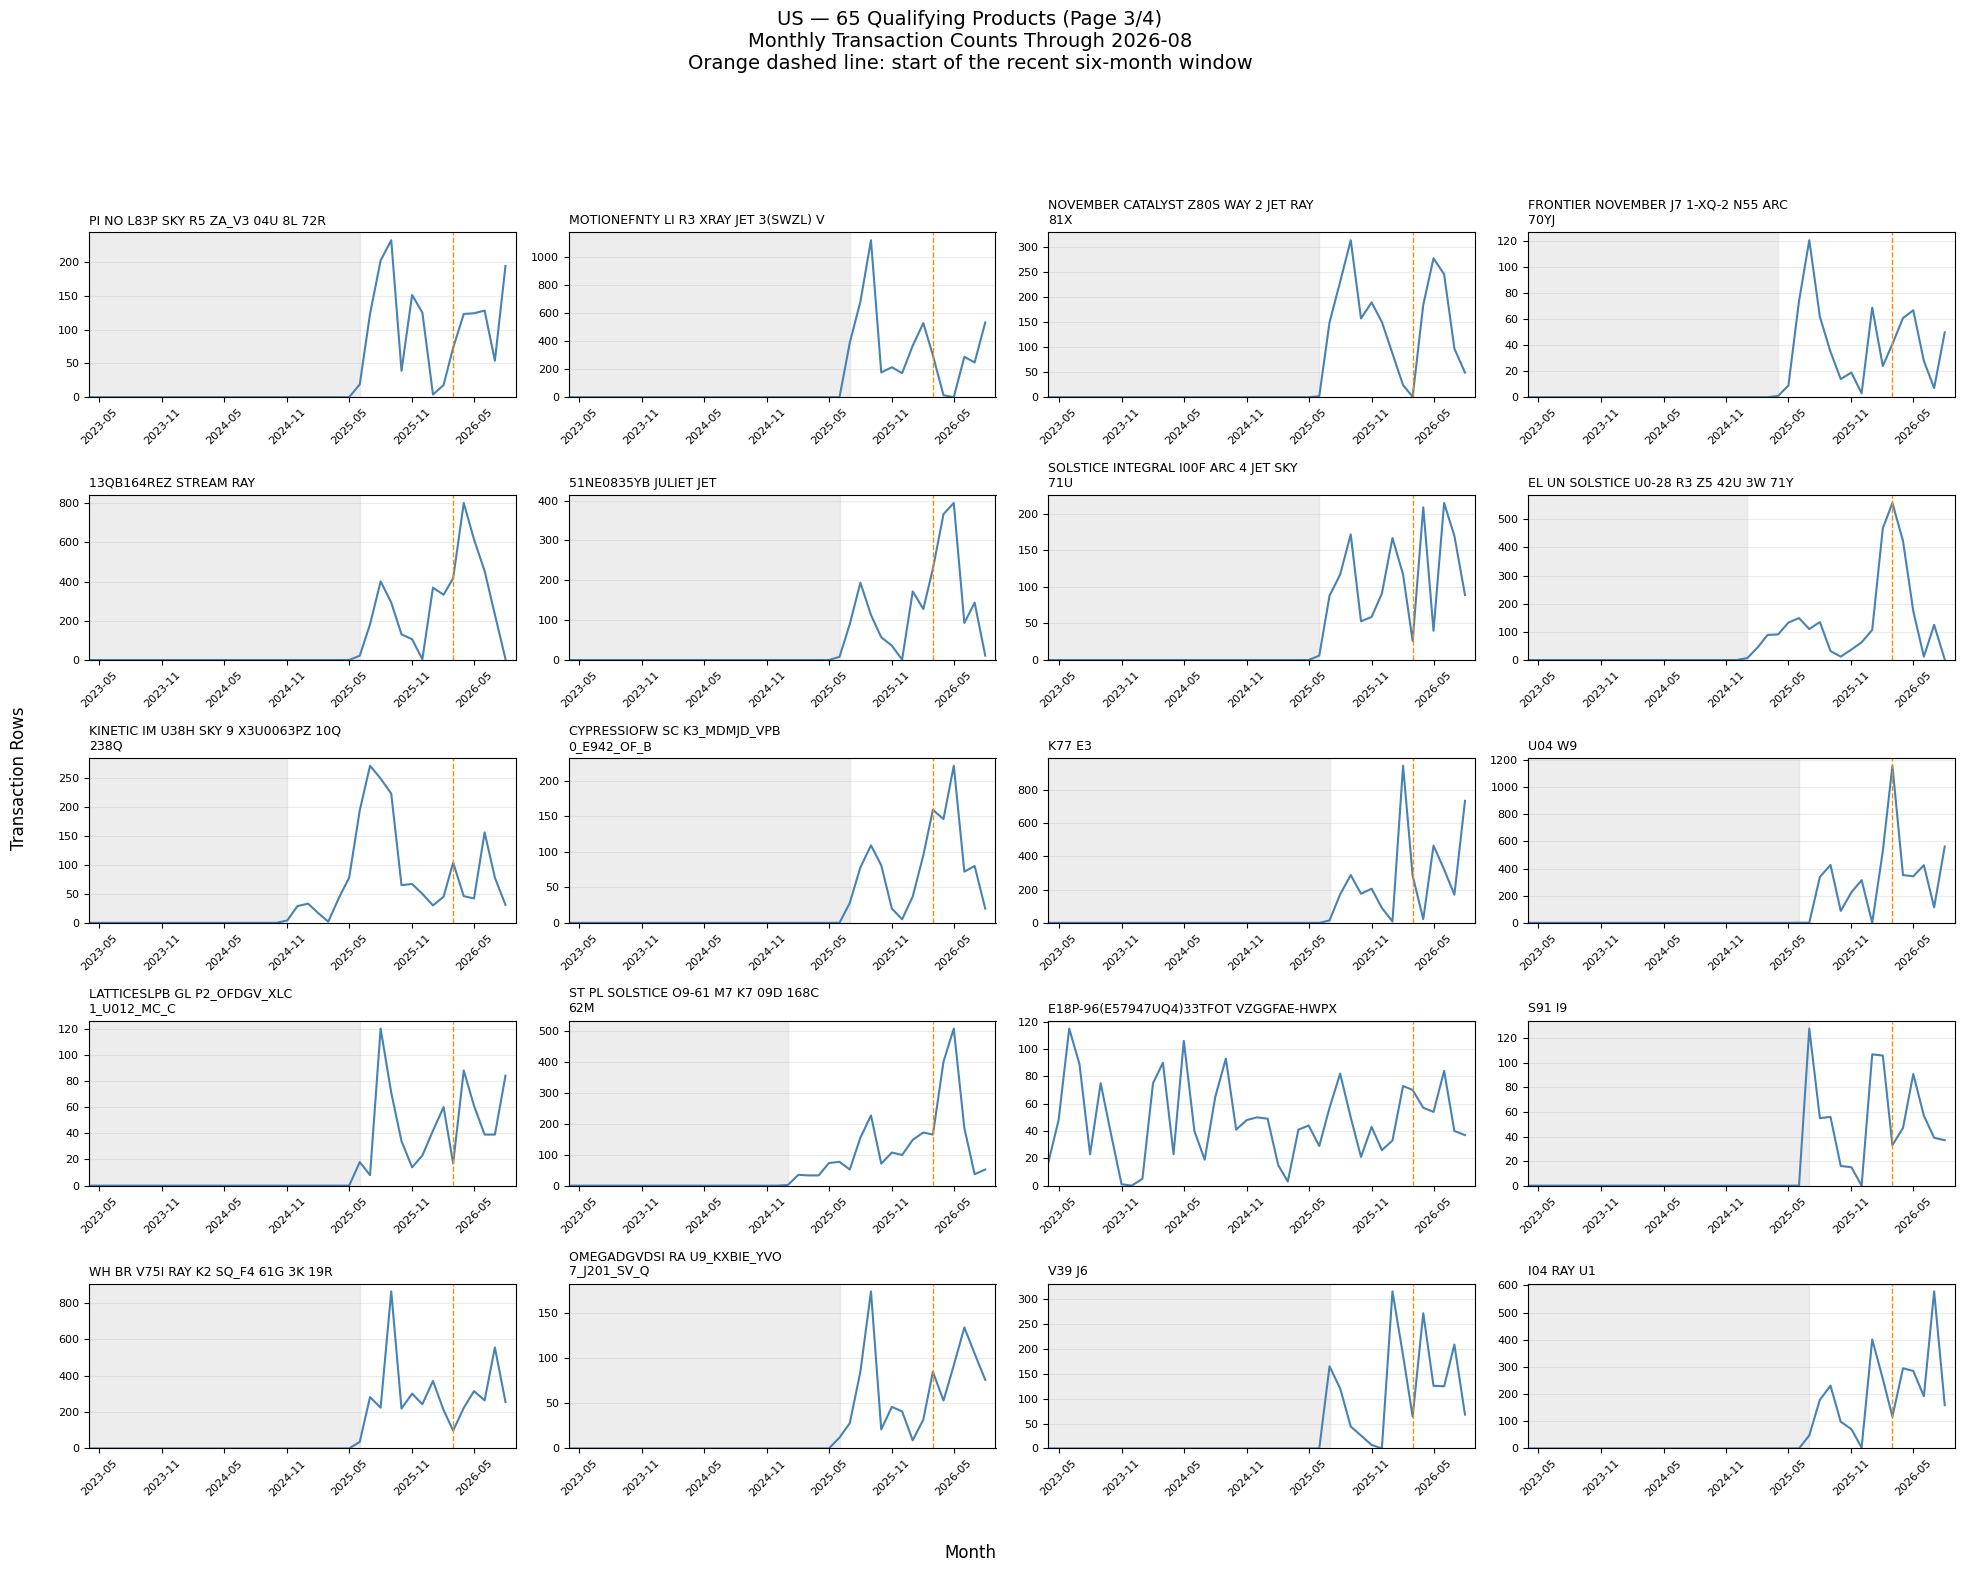

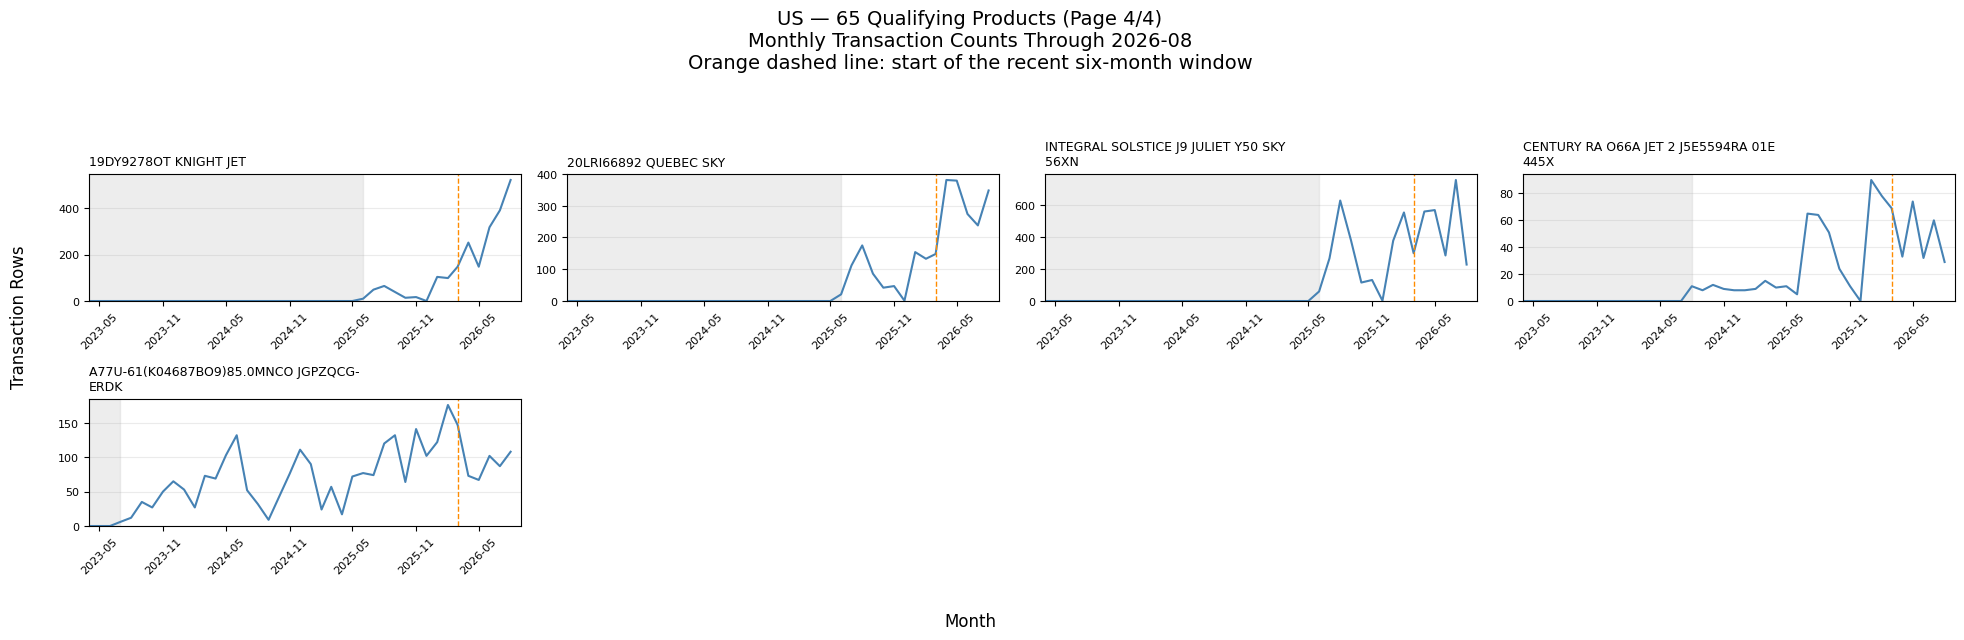

In [19]:
plot_selected_transactions("US")

In [ ]:
from pathlib import Path

output_dir = Path.cwd() / "selected_product_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

us_selected_keys = country_results["US"]["selected_products"][
    PRODUCT_KEYS
].drop_duplicates()

# Export full-history transactions without removing duplicate rows.
us_transactions = country_data["US"].merge(
    us_selected_keys,
    on=PRODUCT_KEYS,
    how="inner",
    validate="many_to_one",
)

us_product_list = (
    us_transactions[["product_name", "product_family", "product_type", "product_id"]]
    .drop_duplicates()
    .sort_values(["product_family", "product_name", "product_id"])
    .reset_index(drop=True)
)

us_transactions.to_csv(
    output_dir / "US_selected_transactions.csv",
    index=False,
    encoding="utf-8-sig",
)

us_product_list.to_csv(
    output_dir / "US_selected_product_list.csv",
    index=False,
    encoding="utf-8-sig",
)

print(f"US: {len(us_selected_keys)} selected product groups.")
print(f"Exported {len(us_transactions):,} transaction rows.")
print("Saved to:", output_dir.resolve())

US: 65 selected product groups.
Exported 129,920 transaction rows.
Saved to: /Users/AustinZhang/Desktop/Capstone/stage 1/selected_product_outputs


## CA Product Selection
- Require more than 50 transactions in total during the latest six complete months, with transaction records in at least three of those months.
- Divide the preceding 18 months into three six-month periods. Require more than 50 transactions in at least two periods.

In [10]:
ca_recent, ca_history = build_product_statistics("CA")

ca_history["passes_period"] = ca_history["transaction_count"].gt(
    CA_HISTORY_TRANSACTIONS
)

ca_history_summary = (
    ca_history.groupby(PRODUCT_KEYS, observed=True)
    .agg(
        history_periods_passed=("passes_period", "sum"),
        historical_transactions=("transaction_count", "sum"),
    )
    .reset_index()
)

ca_summary = ca_recent.merge(
    ca_history_summary,
    on=PRODUCT_KEYS,
    validate="one_to_one",
)

ca_summary["qualifies"] = (
    ca_summary["recent_transactions"].gt(CA_RECENT_TRANSACTIONS)
    & ca_summary["recent_active_months"].ge(CA_RECENT_ACTIVE_MONTHS)
    & ca_summary["history_periods_passed"].ge(CA_MIN_HISTORY_PERIODS)
)

ca_selected = (
    ca_summary.loc[ca_summary["qualifies"]]
    .sort_values(PRODUCT_KEYS)
    .reset_index(drop=True)
)

country_results["CA"] = {
    "selected_products": ca_selected,
    "all_products": ca_summary,
    "history_detail": ca_history,
}

print(f"CA: {len(ca_selected)} qualifying product groups.")

CA: 24 qualifying product groups.


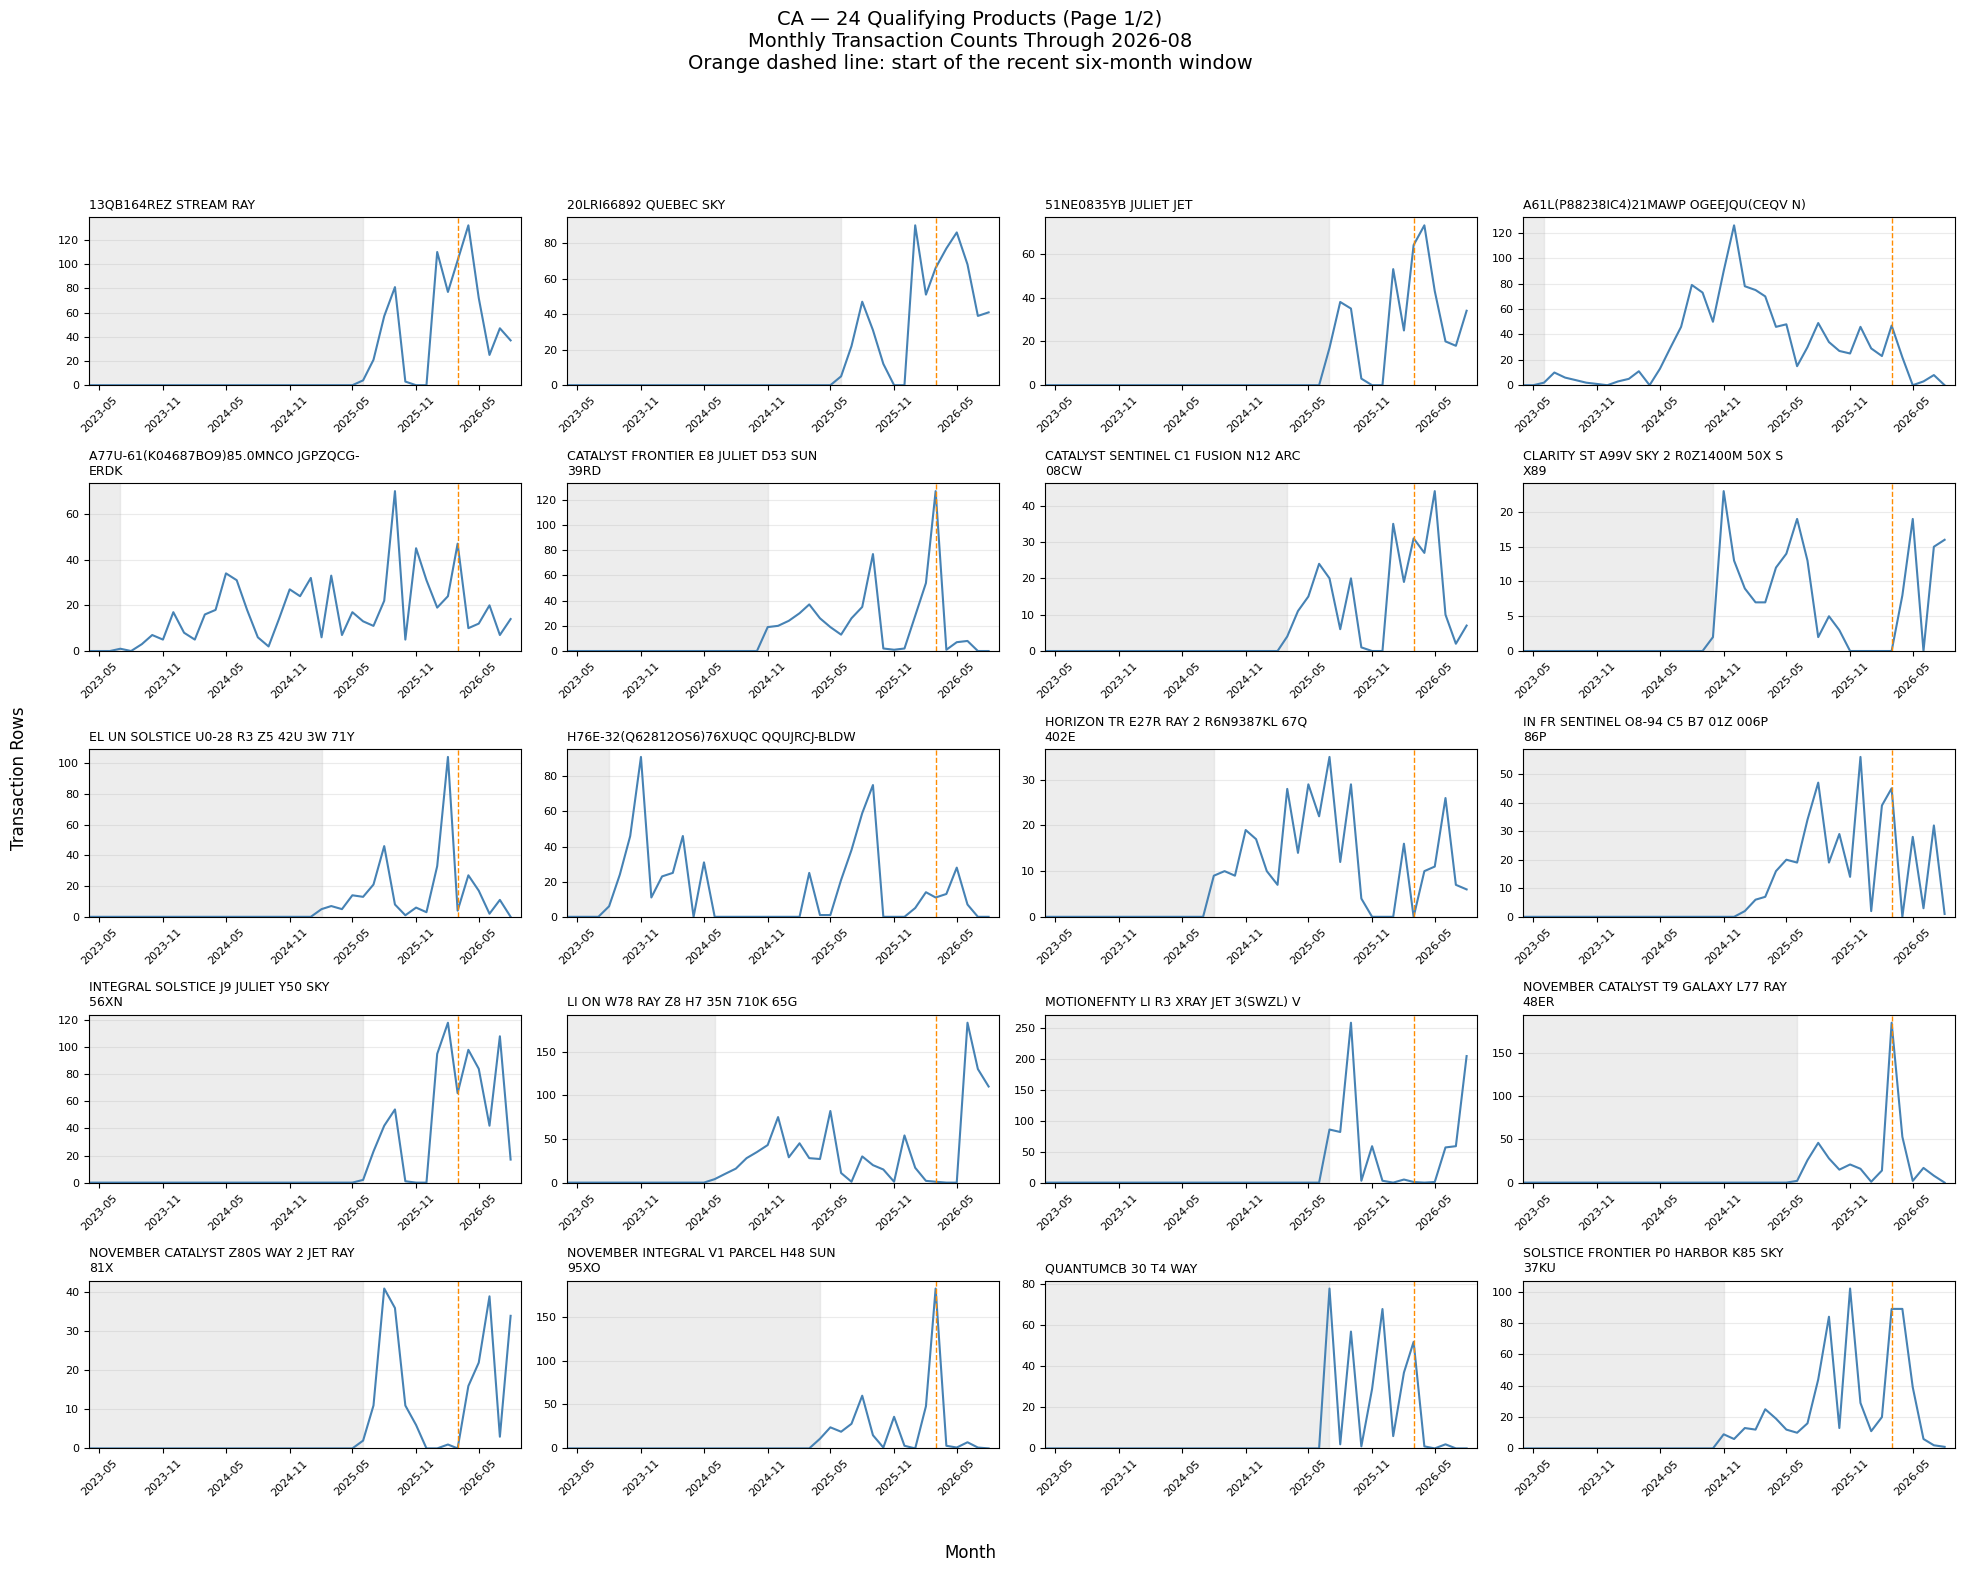

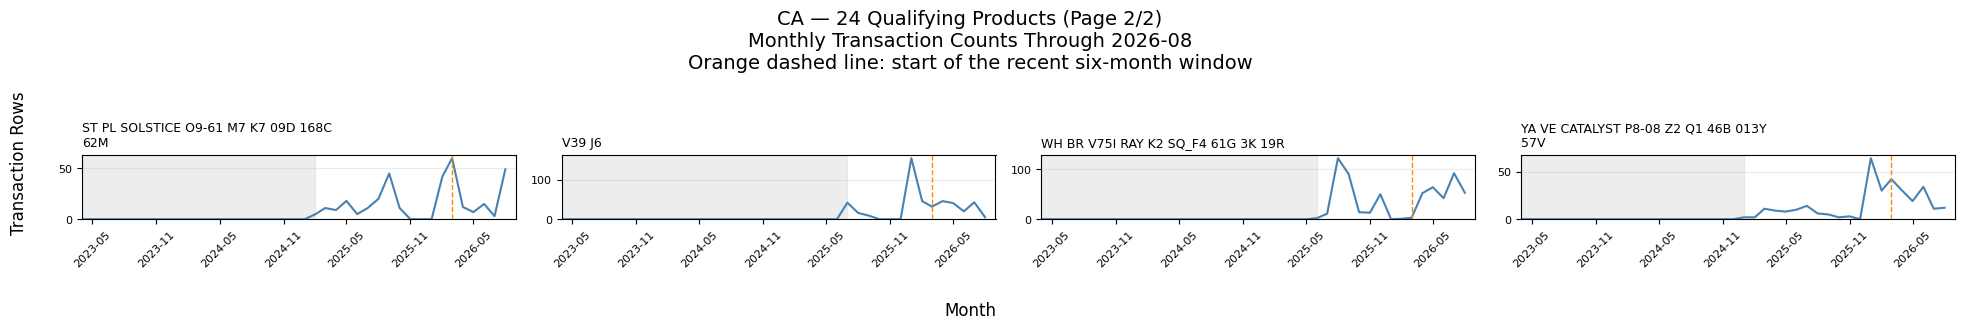

In [11]:
plot_selected_transactions("CA")

In [ ]:
from pathlib import Path

output_dir = Path.cwd() / "selected_product_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

ca_selected_keys = country_results["CA"]["selected_products"][
    PRODUCT_KEYS
].drop_duplicates()

# Export full-history transactions without removing duplicate rows.
ca_transactions = country_data["CA"].merge(
    ca_selected_keys,
    on=PRODUCT_KEYS,
    how="inner",
    validate="many_to_one",
)

ca_product_list = (
    ca_transactions[["product_name", "product_family", "product_type", "product_id"]]
    .drop_duplicates()
    .sort_values(["product_family", "product_name", "product_id"])
    .reset_index(drop=True)
)

ca_transactions.to_csv(
    output_dir / "CA_selected_transactions.csv",
    index=False,
    encoding="utf-8-sig",
)

ca_product_list.to_csv(
    output_dir / "CA_selected_product_list.csv",
    index=False,
    encoding="utf-8-sig",
)

print(f"CA: {len(ca_selected_keys)} selected product groups.")
print(f"Exported {len(ca_transactions):,} transaction rows.")
print("Saved to:", output_dir.resolve())

CA: 24 selected product groups.
Exported 12,777 transaction rows.
Saved to: /Users/AustinZhang/Desktop/Capstone/stage 1/selected_product_outputs
